<a href="https://colab.research.google.com/github/IsnaaChaansukauangg67/Coding-Lainnya/blob/main/Analisis%20BFS%20dan%20DSF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Mendefinisikan Graf

In [2]:

# Representasi graf menggunakan Adjacency List (Dictionary)

graph = {
    'A': ['B', 'C', 'D'],
    'B': ['E', 'F'],
    'C': [],
    'D': ['G'],
    'E': [],
    'F': [],
    'G': []
}


# Visualisasi graf

print("Representasi Graf:")
print("===================")

for node, neighbors in graph.items():
    print(f"{node} -> {neighbors}")


Representasi Graf:
A -> ['B', 'C', 'D']
B -> ['E', 'F']
C -> []
D -> ['G']
E -> []
F -> []
G -> []


2. Implementasi dari Algoritma BFS

In [4]:

from collections import deque

def bfs(graph, start, goal):
    visited = []  # Node yang sudah dikunjungi
    queue = deque([[start]])  # Antrian berisi jalur yang akan ditelusuri

    while queue:
        path = queue.popleft()  # Ambil jalur pertama
        node = path[-1]  # Ambil node terakhir dari jalur

        if node not in visited:
            visited.append(node)

            # Jika node saat ini adalah tujuan
            if node == goal:
                return path, visited

            # Tambahkan tetangga ke antrian
            for neighbor in graph[node]:
                new_path = list(path)
                new_path.append(neighbor)
                queue.append(new_path)

    return None, visited


3. Implementasi dari Algoritma DFS

In [5]:

def dfs(graph, start, goal, path=None, visited=None):

    if path is None:
        path = [start]

    if visited is None:
        visited = []

    visited.append(start)

    # Jika node saat ini adalah tujuan
    if start == goal:
        return path, visited

    # Telusuri setiap tetangga
    for neighbor in graph[start]:

        if neighbor not in visited:
            new_path, new_visited = dfs(
                graph,
                neighbor,
                goal,
                path + [neighbor],
                visited
            )

            if new_path:
                return new_path, new_visited

    return None, visited


4. Perbandingan BFS dengan DFS

In [6]:

# Menentukan node awal dan node tujuan
start_node = 'A'
goal_node = 'G'

# Menjalankan algoritma BFS
path_bfs, visited_bfs = bfs(graph, start_node, goal_node)

# Menjalankan algoritma DFS
path_dfs, visited_dfs = dfs(graph, start_node, goal_node)


# Menampilkan hasil BFS
print("=== HASIL BFS ===")
print("Node awal:", start_node)
print("Node tujuan:", goal_node)
print("Urutan node dikunjungi:", visited_bfs)
print("Jalur ditemukan:", path_bfs)


# Menampilkan hasil DFS
print("\n=== HASIL DFS ===")
print("Node awal:", start_node)
print("Node tujuan:", goal_node)
print("Urutan node dikunjungi:", visited_dfs)
print("Jalur ditemukan:", path_dfs)


=== HASIL BFS ===
Node awal: A
Node tujuan: G
Urutan node dikunjungi: ['A', 'B', 'C', 'D', 'E', 'F', 'G']
Jalur ditemukan: ['A', 'D', 'G']

=== HASIL DFS ===
Node awal: A
Node tujuan: G
Urutan node dikunjungi: ['A', 'B', 'E', 'F', 'C', 'D', 'G']
Jalur ditemukan: ['A', 'D', 'G']


5. Visualisasi dari Jalur yang Dihasilkan

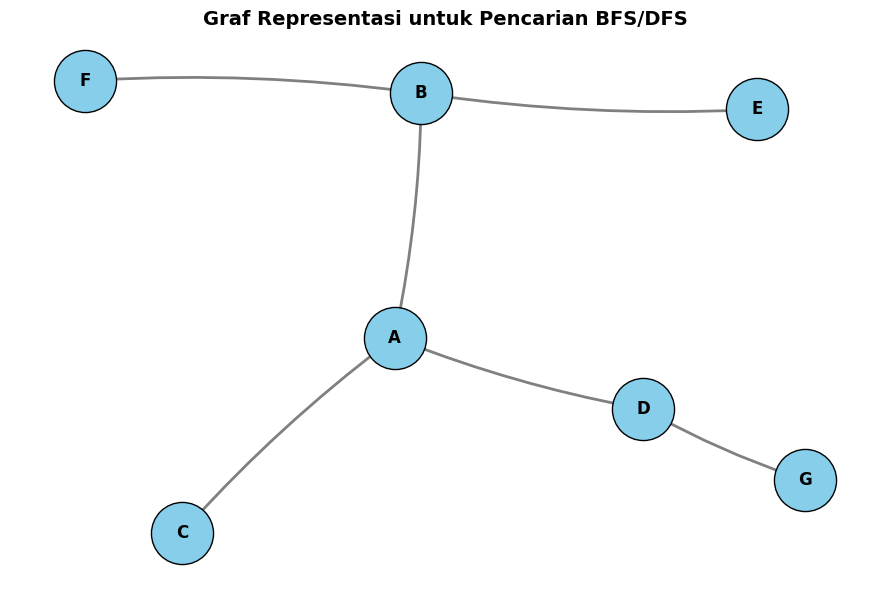

In [7]:

import networkx as nx
import matplotlib.pyplot as plt

# Membuat graf berarah dari adjacency list
G = nx.DiGraph(graph)

# Mengatur ukuran gambar
plt.figure(figsize=(9, 6))

# Mengatur posisi setiap node agar rapi
pos = nx.spring_layout(G, seed=42)

# Menggambar node dan label
nx.draw_networkx_nodes(
    G,
    pos,
    node_size=2000,
    node_color="skyblue",
    edgecolors="black"
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=12,
    font_weight="bold"
)

# Menggambar garis penghubung dan arah panah
nx.draw_networkx_edges(
    G,
    pos,
    arrowstyle="->",
    arrowsize=20,
    edge_color="gray",
    width=2,
    connectionstyle="arc3,rad=0.05"
)

# Memberikan judul
plt.title(
    "Graf Representasi untuk Pencarian BFS/DFS",
    fontsize=14,
    fontweight="bold"
)

# Menghilangkan sumbu koordinat
plt.axis("off")

# Menampilkan graf
plt.tight_layout()
plt.show()


6. Analisis Hasil

In [8]:
print(" Perbandingan Singkat:")
print("- BFS menjelajah semua node di level yang sama sebelum turun ke level berikutnya.")
print("- DFS menjelajah cabang sedalam mungkin sebelum kembali (backtrack).")
print("- BFS cenderung menemukan jalur terpendek, DFS belum tentu.")

 Perbandingan Singkat:
- BFS menjelajah semua node di level yang sama sebelum turun ke level berikutnya.
- DFS menjelajah cabang sedalam mungkin sebelum kembali (backtrack).
- BFS cenderung menemukan jalur terpendek, DFS belum tentu.
